# 03 · Experimento: A → B → C según la duración de la obstrucción (paso 13)

**Pregunta.** Ante una obstrucción en el tramo W30→W29, ¿cómo contienen, retrasan o trasladan la cola las tres estrategias? ¿Cambia la respuesta según cuánto dura la obstrucción?

**Diseño, fijado antes de ejecutar:**

| Elemento | Decisión |
|---|---|
| Comparaciones | En escalera: **B − A** (efecto de coordinar) y **C − B** (efecto de reaccionar a la ocupación). No se compara A con C directamente |
| Factor | Duración de la obstrucción: 0 (control), 1, 3, 5, 10 y 20 min |
| Ventana | Miércoles 2026-03-04, 16:30–18:30; obstrucción a las 17:00; 15 min de calentamiento; 30 min de vaciado |
| Réplicas | **30.** En cada réplica se vuelven a sortear las llegadas con las reglas de la base |
| Números aleatorios comunes | En la misma réplica, A, B y C reciben **exactamente los mismos vehículos** |
| Censura al cierre | Con el vaciado no debería quedar nadie; se comprueba con `pendientes_al_cierre` |

> **Advertencia de honestidad.** La demanda es ficticia y los parámetros del motor son supuestos (notebook 02). Los resultados describen **este modelo**, no la calle real.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
from experimento import correr, ic_pareado
from motor_simpy import Parametros
iv = pd.read_csv(RAIZ / 'datos/procesados/intervalos.csv')
SALIDA = RAIZ / 'resultados/experimento'; SALIDA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
DURACIONES, R = [0, 1, 3, 5, 10, 20], 30

**Lectura.** Preparamos el experimento: 6 duraciones × 3 estrategias × 30 réplicas = 540 corridas del motor. Tarda unos 3 minutos.

## 1. Correr el experimento principal

In [2]:
df = correr(iv, DURACIONES, R)
df.to_csv(SALIDA / 'principal.csv', index=False)
print(len(df), 'corridas | vehículos que no salieron al cierre:', int(df['pendientes_al_cierre'].sum()))

540 corridas | vehículos que no salieron al cierre: 0


**Lectura.** Todos los vehículos salen antes del cierre en todas las corridas: no hay censura y las esperas promedio no están sesgadas a la baja por vehículos que nunca terminaron.

## 2. ¿Por qué diferencias emparejadas?

Como A, B y C de una misma réplica reciben el mismo tráfico, comparamos **réplica por réplica**: diferencia = B − A en la réplica 1, en la réplica 2, … Luego promediamos las 30 diferencias y calculamos su intervalo de confianza (IC) del 95 %:

$$\bar d \pm t_{0.975,\,29}\cdot \frac{s_d}{\sqrt{30}}$$

**Analogía:** para saber si unos zapatos nuevos hacen correr más rápido, conviene que **el mismo** corredor pruebe los dos pares. Así la diferencia entre corredores no se mezcla con el efecto del zapato.

**Cómo leerlo:** si el IC no incluye el 0, la diferencia no se explica por el azar de las llegadas. Un valor negativo significa que el segundo escalón **reduce** la métrica.

In [3]:
def tabla(metrica):
    t = pd.concat([ic_pareado(df, metrica, 'A', 'B'), ic_pareado(df, metrica, 'B', 'C')]).reset_index().round(1)
    t['IC 95 %'] = t.apply(lambda r: f"[{r.ic_inf:.1f}, {r.ic_sup:.1f}]", axis=1)
    return t.pivot(index='duracion_min', columns='comparacion', values=['mean', 'IC 95 %']).round(1)
print('Espera media por vehículo (s)'); display(tabla('espera_media_s'))
print('Tiempo con la cola de la Séptima más allá de W31 (s)'); display(tabla('s_cola_llega_w31'))

Espera media por vehículo (s)


mean               IC 95 %             
comparacion  B − A C − B           B − A        C − B
duracion_min                                         
0            -11.9   0.0  [-12.0, -11.7]   [0.0, 0.0]
1            -11.8   0.0  [-12.0, -11.6]  [-0.0, 0.0]
3            -11.8   0.2  [-12.0, -11.6]   [0.2, 0.3]
5            -11.9   0.5  [-12.1, -11.7]   [0.4, 0.7]
10           -12.3   1.3  [-12.6, -12.0]   [1.1, 1.5]
20           -14.8   3.4  [-15.3, -14.2]   [3.0, 3.7]

Tiempo con la cola de la Séptima más allá de W31 (s)


mean                  IC 95 %                
comparacion   B − A  C − B             B − A           C − B
duracion_min                                                
0               0.0    0.0        [0.0, 0.0]      [0.0, 0.0]
1               0.0    0.0        [0.0, 0.0]      [0.0, 0.0]
3               0.0    6.5        [0.0, 0.0]     [0.3, 12.7]
5              -9.3   56.7     [-15.8, -2.8]    [35.6, 77.8]
10            -80.3  195.2    [-93.5, -67.2]  [174.3, 216.1]
20           -160.2  216.8  [-174.9, -145.5]  [192.1, 241.6]

**Lectura.**

- **B − A en la espera:** coordinar ahorra unos 12 s por vehículo con cualquier duración (casi 15 s con 20 min). Ese ahorro existe aunque no haya obstrucción: es el beneficio normal de la onda verde.
- **B − A en el contagio a W31:** con obstrucciones de hasta 3 min, ninguna estrategia deja que la cola llegue a W31. Con 5, 10 y 20 min, B reduce ese tiempo (unos 80 s menos con 10 min y 160 s menos con 20 min).
- **C − B:** C aumenta un poco la espera (+1.3 s con 10 min) y aumenta claramente el tiempo con la cola en W31 (+195 s con 10 min). C **traslada** la cola hacia arriba.

## 3. Contener, retrasar o trasladar

In [4]:
res = df.groupby(['duracion_min', 'estrategia']).agg(
    espera=('espera_media_s', 'mean'), s_w31=('s_cola_llega_w31', 'mean'), bloqueo_w30=('s_bloqueo_w30', 'mean'),
    cola_max=('cola_max_septima', 'mean'),
    pct_tramo_lleno=('min_hasta_tramo_lleno', lambda x: x.notna().mean() * 100),
    min_tramo_lleno=('min_hasta_tramo_lleno', 'median'),
    pct_llega_w31=('min_hasta_w31', lambda x: x.notna().mean() * 100),
    min_llega_w31=('min_hasta_w31', 'median')).round(1)
res.to_csv(SALIDA / 'resumen.csv'); res

espera   s_w31  bloqueo_w30  cola_max  \
duracion_min estrategia                                          
0            A             27.5     0.0          0.0      21.6   
             B             15.7     0.0          0.0      21.6   
             C             15.7     0.0          0.0      21.6   
1            A             27.6     0.0          0.0      21.6   
             B             15.8     0.0          0.0      21.6   
             C             15.8     0.0          0.0      21.6   
3            A             28.2     0.0          9.5      22.2   
             B             16.4     0.0          8.3      21.6   
             C             16.7     6.5          0.0      29.0   
5            A             29.6    13.5         40.7      29.5   
             B             17.7     4.2         39.5      24.6   
             C             18.3    60.8          0.0      42.3   
10           A             36.0   295.3        132.0      64.1   
             B             23.7   215.0        154.3      55.9   
             C             25.0   410.2          0.0      78.2   
20           A             62.1  1179.3        330.5     133.6   
             B             47.4  1019.2        387.3     125.3   
             C             50.8  1236.0          0.0     148.5   

                         pct_tramo_lleno  min_tramo_lleno  pct_llega_w31  \
duracion_min estrategia                                                    
0            A                      23.3             25.5            0.0   
             B                       0.0              NaN            0.0   
             C                       0.0              NaN            0.0   
1            A                      23.3             25.5            0.0   
             B                       0.0              NaN            0.0   
             C                       0.0              NaN            0.0   
3            A                      70.0              2.3            0.0   
             B                      56.7              2.2            0.0   
             C                       0.0              NaN           26.7   
5            A                      96.7              2.5           30.0   
             B                      93.3              3.2            6.7   
             C                       0.0              NaN           73.3   
10           A                     100.0              2.5          100.0   
             B                     100.0              3.2           93.3   
             C                       0.0              NaN          100.0   
20           A                     100.0              2.5          100.0   
             B                     100.0              3.2          100.0   
             C                       0.0              NaN          100.0   

                         min_llega_w31  
duracion_min estrategia                 
0            A                     NaN  
             B                     NaN  
             C                     NaN  
1            A                     NaN  
             B                     NaN  
             C                     NaN  
3            A                     NaN  
             B                     NaN  
             C                     3.9  
5            A                     4.9  
             B                     4.4  
             C                     4.8  
10           A                     6.0  
             B                     7.4  
             C                     5.4  
20           A                     6.0  
             B                     7.6  
             C                     5.4

**Lectura.** Columnas: `pct_…` = porcentaje de réplicas en que ocurre el suceso; `min_…` = mediana de los minutos que tarda en ocurrir desde que empieza la obstrucción.

- **Retrasar:** con obstrucciones de 5 min o más, el tramo se llena en unos 2.5 min en A y en unos 3.2 min en B. La coordinación compra unos 40 s de margen, porque B empieza con el tramo más vacío. Ese margen solo decide algo en bloqueos cortos: con 3 min, el tramo se llena en el 70 % de las réplicas de A y en el 57 % de las de B; con 5 min, la cola llega a W31 en el 30 % de A y solo en el 7 % de B. En bloqueos largos todo se llena igual. Es la idea A16.
- **Contener:** C nunca llena el tramo y prácticamente elimina el bloqueo físico de W30 (`bloqueo_w30` ≈ 0).
- **Trasladar:** el precio de C es una cola más larga en la Séptima, que llega a W31 antes y durante más tiempo. Lo que C protege dentro del tramo lo traslada a la cuadra anterior.
- **Sin obstrucción**, A llena el tramo de vez en cuando (desfase de 40 s): los carros esperan en W29 en lugar de pasar.

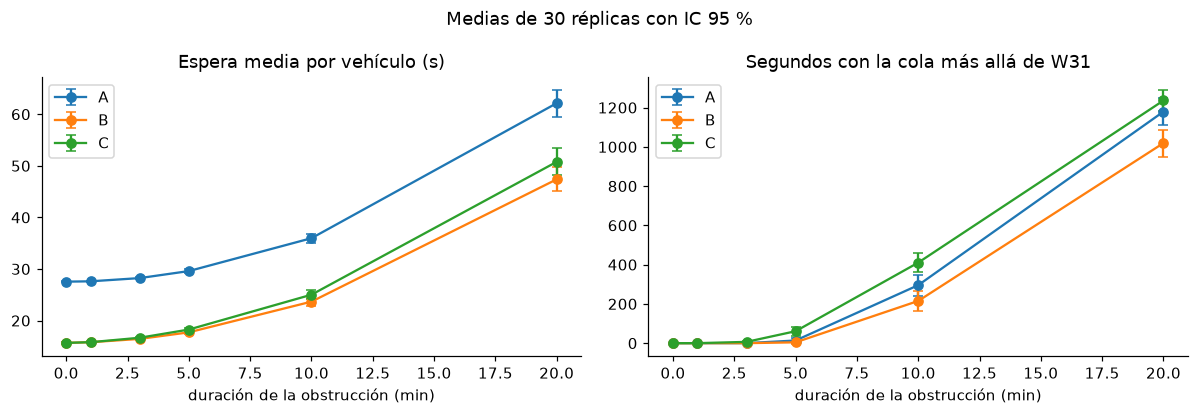

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for e, g in df.groupby('estrategia'):
    m = g.groupby('duracion_min')
    for a, col in zip(ax, ['espera_media_s', 's_cola_llega_w31']):
        mu, se = m[col].mean(), m[col].std() / np.sqrt(R)
        a.errorbar(mu.index, mu, yerr=1.96 * se, marker='o', capsize=3, label=e)
ax[0].set_title('Espera media por vehículo (s)'); ax[1].set_title('Segundos con la cola más allá de W31')
for a in ax: a.set_xlabel('duración de la obstrucción (min)'); a.legend()
fig.suptitle('Medias de 30 réplicas con IC 95 %'); plt.tight_layout(); plt.savefig(SALIDA / 'figura_principal.png'); plt.show()

**Lectura.** A la izquierda, B queda siempre por debajo de A en un nivel casi constante, y la obstrucción sube las tres curvas. A la derecha, el contagio a W31 empieza a aparecer a partir de unos 5 minutos de obstrucción. C (verde) queda por encima de B: la regulación por ocupación, con estos umbrales, empeora la cuadra anterior.

## 4. Sensibilidad: ¿dependen las conclusiones de los supuestos?

Usamos la obstrucción de 10 min, las mismas 30 réplicas y movemos un supuesto a la vez:

1. **Desfase independiente de A** (0, 20 y 40 s). El diseño exige probar varios para no favorecer a nadie por accidente.
2. **Umbrales de C** (H, L) = (0.6, 0.4), (0.8, 0.6) y (0.95, 0.8).
3. **Severidad:** 1 carril bloqueado en lugar de 2.

In [6]:
P = Parametros(); d10 = df[df.duracion_min == 10]; b10 = d10[d10.estrategia == 'B']
filas = []
for x in [0, 20, 40]:
    a = correr(iv, [10], R, base=replace(P, desfase_w29_indep=x), estrategias='A')
    for m in ['espera_media_s', 's_cola_llega_w31']:
        r = ic_pareado(pd.concat([a, b10]), m, 'A', 'B').iloc[0]
        filas.append(('B − A', f'desfase A = {x} s', m, r['mean'], r.ic_inf, r.ic_sup))
for h, l in [(0.6, 0.4), (0.8, 0.6), (0.95, 0.8)]:
    c = correr(iv, [10], R, base=replace(P, frac_H=h, frac_L=l), estrategias='C')
    for m in ['espera_media_s', 's_cola_llega_w31']:
        r = ic_pareado(pd.concat([b10, c]), m, 'B', 'C').iloc[0]
        filas.append(('C − B', f'H = {h}, L = {l}', m, r['mean'], r.ic_inf, r.ic_sup))
s = correr(iv, [10], R, base=replace(P, carriles_bloqueados=1))
for comp, (de, a_) in {'B − A': ('A', 'B'), 'C − B': ('B', 'C')}.items():
    for m in ['espera_media_s', 's_cola_llega_w31']:
        r = ic_pareado(s, m, de, a_).iloc[0]
        filas.append((comp, '1 carril bloqueado', m, r['mean'], r.ic_inf, r.ic_sup))
sens = pd.DataFrame(filas, columns=['comparación', 'variante', 'métrica', 'diferencia', 'ic_inf', 'ic_sup']).round(1)
sens.to_csv(SALIDA / 'sensibilidad.csv', index=False); sens

,comparación,variante,métrica,diferencia,ic_inf,ic_sup
0,B − A,desfase A = 0 s,espera_media_s,-4.4,-5.1,-3.8
1,B − A,desfase A = 0 s,s_cola_llega_w31,107.7,79.3,136.0
2,B − A,desfase A = 20 s,espera_media_s,-3.2,-3.3,-3.0
3,B − A,desfase A = 20 s,s_cola_llega_w31,-56.8,-65.7,-47.9
4,B − A,desfase A = 40 s,espera_media_s,-12.3,-12.6,-12.0
5,B − A,desfase A = 40 s,s_cola_llega_w31,-80.3,-93.5,-67.2
6,C − B,"H = 0.6, L = 0.4",espera_media_s,2.7,2.3,3.0
7,C − B,"H = 0.6, L = 0.4",s_cola_llega_w31,296.5,268.1,324.9
8,C − B,"H = 0.8, L = 0.6",espera_media_s,1.3,1.1,1.5
9,C − B,"H = 0.8, L = 0.6",s_cola_llega_w31,195.2,174.3,216.1


**Lectura (la parte más importante para no exagerar).**

- **Espera:** B gana a A con cualquier desfase de referencia, pero el tamaño de la ventaja depende mucho de ese desfase: unos 12 s contra el de 40 s, y solo 3–4 s contra los de 0 y 20 s. Reportar "B ahorra 12 s" sin decir contra qué A se comparó sería engañoso.
- **Contagio a W31:** el signo **cambia**. Contra A con desfase 0, B deja la cola en W31 **más** tiempo (unos +108 s). Una posible explicación: con verdes simultáneos, el tramo descarga en W29 justo cuando W30 deja de alimentarlo. Por lo tanto, "la coordinación contiene el *spillback*" **no es robusto** en este modelo; "la coordinación reduce la espera" sí lo es.
- **Umbrales de C:** cuanto más alto es H, menos daño hace C, pero con ninguno de los tres pares C supera a B en W31. El bloqueo físico de W30 desaparece en todos los casos.
- **Severidad:** con solo 1 carril bloqueado, la salida del tramo conserva capacidad suficiente (ρ < 1). No hay contagio y C nunca se activa. La obstrucción solo importa si deja la salida por debajo de la demanda.

## 5. Conclusiones del experimento (modelo ficticio)

1. **Coordinar (A → B)** reduce la espera de forma robusta. El efecto sobre el contagio de la cola depende del plan de referencia, y solo se nota en obstrucciones de 5 min o más.
2. **La coordinación da margen, no inmunidad:** retrasa el llenado del tramo (≈ 40 s), lo que basta para bloqueos cortos y es irrelevante en los largos.
3. **Reaccionar a la ocupación (B → C)** evita bloquear el cruce de W30, pero con estos umbrales **traslada** la cola a la cuadra anterior y alarga la espera.
4. **Supuestos clave por confirmar:** el plan de referencia de A, los umbrales de C y la severidad de la obstrucción. Los resultados son sensibles a los tres.
5. **Siguiente:** exportar corridas representativas al contrato JSON para la maqueta 3D y redactar el informe con estas limitaciones.